# Atelier AI — Behavioral EDA

## Objective

Investigate customer activity, article popularity, repeat purchases
and temporal variation to formulate testable hypotheses for candidate
generation and feature engineering.

The analysis uses transactions strictly before 2020-09-09.
Validation and local-test targets remain outside the behavioral
analysis scope.

Source characteristics and handling decisions are documented in the
[data card](../docs/data_card.md).
Temporal boundaries follow the
[evaluation strategy](../docs/evaluation.md).

The notebook runs independently from the
[data-foundation notebook](data_foundation.ipynb).

## 1. Environment

The project virtual environment provides the analysis dependencies
and the installed atelier_ai package.

Each analysis must run from a fresh kernel without relying on
variables created in another notebook.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import atelier_ai

from collections import Counter

import plotly.express as px

from tempfile import TemporaryDirectory

import duckdb

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Package location:", Path(atelier_ai.__file__).resolve())
print("pandas version:", pd.__version__)
print("DuckDB version:", duckdb.__version__)

Python version: 3.12.14
Python executable: /Users/oumar/Developer/portfolio/atelier-ai-project/.venv/bin/python
Package location: /Users/oumar/Developer/portfolio/atelier-ai-project/src/atelier_ai/__init__.py
pandas version: 3.0.6
DuckDB version: 2.0.0


## 2. Analysis Contract

### 2.1. Time Boundaries and Population

The analysis interval is [2018-09-20, 2020-09-09):
the start is included and the end is excluded.

The behavioral population consists of customers with at least one
observed transaction within this interval. Inclusion does not depend
on purchases in the validation or test periods.

Initial behavioral analyses use all eligible transaction rows.
A future modeling cohort and modeling lookback are separate choices.

First and last purchases refer to the first and last observed records
within the declared interval. They do not establish lifetime behavior,
registration dates or article launch dates.

Customers without an observed history require separate coverage
diagnostics and are not represented by active-customer averages.

Analyses used to design features exclude validation and test targets.
Features calculated later at a historical prediction cutoff must use
only records strictly before that particular cutoff.

In [2]:
PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
RAW_DATA_DIRECTORY = PROJECT_ROOT / "data" / "raw" / "hm"

EDA_START = pd.Timestamp("2018-09-20")
EDA_END_EXCLUSIVE = pd.Timestamp("2020-09-09")

CHUNK_ROWS = 100_000
# Reference established by the data-foundation analysis.
EXPECTED_EDA_TRANSACTION_ROWS = 31_292_772

RECENT_ACTIVITY_DAYS = 28

TOP_ARTICLES = 20

if not EDA_START < EDA_END_EXCLUSIVE:
    raise ValueError(
        "EDA start must precede its exclusive end."
    )

if not (RAW_DATA_DIRECTORY / "transactions_train.csv").is_file():
    raise FileNotFoundError(
        "Required source file: transactions_train.csv"
    )

print("Start included:", EDA_START.date())
print("End excluded:", EDA_END_EXCLUSIVE.date())
print(
    "Calendar days:",
    (EDA_END_EXCLUSIVE - EDA_START).days,
)
print("Transaction source found.")

Start included: 2018-09-20
End excluded: 2020-09-09
Calendar days: 720
Transaction source found.


### 2.2. Measurement Definitions

| Measure | Definition | Interpretation boundary |
|---|---|---|
| Transaction rows | Number of retained source rows | Not an identified order or basket count |
| Observed purchase days | Distinct transaction dates for a customer | Several rows on the same day count as one day |
| Distinct purchased articles | Distinct article_id values within the announced group and period | Repeated purchases do not increase this count |
| Observed buyers | Distinct customers purchasing an article within the interval | Buyer counts cannot be summed across articles to obtain distinct customers |
| Customer recency | Calendar-day difference between the reference cutoff and the last observed purchase | A purchase on 2020-09-08 has a recency of one day at the 2020-09-09 cutoff |

Source transaction repetitions are retained.
Distinct article relevance for ranking evaluation is defined separately.

Every proportion must specify its denominator.
Transaction-based shares and customer-based shares answer different
questions.

### 2.3. Aggregate Requirements

These tables describe the analytical requirements.
They will be constructed progressively during the corresponding
analysis stages.

| Aggregate | One row represents | Required measures |
|---|---|---|
| Daily activity | One calendar date | Transaction-row count and source observation flag |
| Customer activity | One observed customer | Rows, purchase days, distinct articles, first and last observed purchase, recency |
| Article activity | One observed article | Rows, distinct buyers, first and last observed purchase |
| Customer–article history | One observed customer–article pair | Rows, distinct purchase days, first and last observed purchase |
| Category activity | One date and classification code | Transaction rows and period totals needed for category shares |
| Customer–category preferences | One observed customer and classification code | Rows, distinct articles and customer totals needed for preference shares |

Distinct counts must remain exact across chunk boundaries.
Large customer–article tables are not assumed to fit simultaneously
in memory.

### 2.4. Metadata and Interpretation Policy

- Preserve exact string identifiers and retained transaction repetitions.
- Use article_id as the recommendation identifier.
- Treat product_code as a grouping field.
- Filter eligible transactions before behavioral aggregation.
- Validate many-to-one metadata joins and reconcile row counts.
- Classification-based descriptions refer to the acquired metadata
  snapshot; historical availability is not established.
- Do not use customer fields with unresolved observation dates to
  define behavioral segments in this initial analysis.
- Preserve unresolved categories and missing-value meanings.
- Retain source price units and sales-channel codes.
- Do not infer stock availability, exposure, causality or business impact.

In [3]:
from contextlib import closing

from atelier_ai.data_io import read_source_chunks
from atelier_ai.temporal import (
    build_daily_activity,
    interval_mask,
)

## 3. Eligible Transaction History

### 3.1. Chunked Date Reading

The initial scope check reads only the transaction-date column.

Each source chunk is processed independently:
1. Parse dates into a temporary datetime representation.
2. Select the declared interval [EDA_START, EDA_END_EXCLUSIVE).
3. Yield the corresponding source date rows.

Source files and retained date strings remain unchanged.
Missing or unparseable dates stop the calculation.

Reading is incremental. Filtered chunks are not accumulated into
a complete transaction DataFrame.

The reader may traverse dates outside the analysis interval.
Only eligible rows are passed to downstream aggregation.

In [4]:
def iter_eda_chunks(columns):
    """Yield requested source columns within the EDA interval."""
    if "t_dat" not in columns:
        raise ValueError(
            "The date column is required for temporal filtering."
        )

    with read_source_chunks(
        RAW_DATA_DIRECTORY / "transactions_train.csv",
        columns=columns,
        chunk_rows=CHUNK_ROWS,
    ) as reader:
        for chunk in reader:
            parsed_dates = pd.to_datetime(
                chunk["t_dat"],
                format="%Y-%m-%d",
                errors="raise",
            )

            if parsed_dates.isna().any():
                raise ValueError(
                    "Transaction dates must be complete."
                )

            eligible = interval_mask(
                parsed_dates,
                EDA_START,
                EDA_END_EXCLUSIVE,
            )

            eligible_rows = chunk.loc[eligible, columns]

            if not eligible_rows.empty:
                yield eligible_rows

### 3.2. Limited Reader Check

Inspect the first nonempty eligible chunk to verify the reader,
date conversion and interval selection.

The summary describes this chunk only.
It does not establish complete-file coverage or total transaction counts.

Close the generator explicitly after this early stop so that its
underlying source reader is also closed.

In [5]:
with closing(
    iter_eda_chunks(columns=["t_dat"])
) as eda_chunks:
    first_eda_chunk = next(eda_chunks, None)

if first_eda_chunk is None:
    raise ValueError(
        "No transaction dates were found in the EDA interval."
    )

preview_dates = pd.to_datetime(
    first_eda_chunk["t_dat"],
    format="%Y-%m-%d",
    errors="raise",
)

preview_in_scope = interval_mask(
    preview_dates,
    EDA_START,
    EDA_END_EXCLUSIVE,
)

if not preview_in_scope.all():
    raise ValueError(
        "The filtered chunk contains dates outside the EDA interval."
    )

first_chunk_summary = pd.DataFrame([{
    "retained_rows": len(first_eda_chunk),
    "first_date": preview_dates.min().date(),
    "last_date": preview_dates.max().date(),
    "all_dates_in_scope": bool(preview_in_scope.all()),
}])

first_chunk_summary

,retained_rows,first_date,last_date,all_dates_in_scope
0,100000,2018-09-20,2018-09-22,True


### 3.3. Complete Daily Aggregation

Consume a new filtered reader from the beginning of the source file.

The existing daily-activity function accumulates transaction-row
counts across chunks and returns a complete daily calendar between
the first and last retained dates.

Repeated source transaction rows remain included.

The resulting table contains daily counts, not individual
transactions or customer-level histories.

In [6]:
print(
    "Counting transaction dates within the EDA interval...",
    flush=True,
)

with closing(
    iter_eda_chunks(columns=["t_dat"])
) as eda_chunks:
    daily_activity_eda, eda_transaction_rows = (
        build_daily_activity(eda_chunks)
    )

print(
    f"Completed: {eda_transaction_rows:,} "
    "eligible transaction rows."
)

Counting transaction dates within the EDA interval...
Completed: 31,292,772 eligible transaction rows.


### 3.4. Scope Reconciliation

Check that:
- the retained row count matches the data-foundation reference;
- daily counts sum to the retained row count;
- the daily calendar matches the complete intended interval;
- every retained date precedes the exclusive cutoff.

A matching row total alone does not establish correct temporal
boundaries. Calendar and boundary checks are therefore explicit.

In [7]:
expected_eda_calendar = pd.date_range(
    start=EDA_START,
    end=EDA_END_EXCLUSIVE - pd.Timedelta(days=1),
    freq="D",
)

scope_checks = pd.Series(
    {
        "row_count_matches_foundation": (
            eda_transaction_rows
            == EXPECTED_EDA_TRANSACTION_ROWS
        ),
        "daily_counts_reconcile": (
            int(daily_activity_eda["transaction_rows"].sum())
            == eda_transaction_rows
        ),
        "calendar_matches_scope": (
            pd.DatetimeIndex(
                daily_activity_eda["date"]
            ).equals(expected_eda_calendar)
        ),
        "all_dates_before_cutoff": bool(
            daily_activity_eda["date"]
            .lt(EDA_END_EXCLUSIVE)
            .all()
        ),
    },
    name="passed",
)

if not scope_checks.all():
    failed_checks = scope_checks.index[
        ~scope_checks
    ].tolist()

    raise ValueError(
        f"EDA scope checks failed: {failed_checks}"
    )

scope_checks.to_frame()

,passed
row_count_matches_foundation,True
daily_counts_reconcile,True
calendar_matches_scope,True
all_dates_before_cutoff,True


### 3.5. Retained Scope Summary

Report the retained interval, calendar coverage and transaction-row
count.

A date without source rows would be reported explicitly.
It would not automatically receive a business explanation.

In [8]:
eda_scope_summary = pd.DataFrame(
    [
        ("start_inclusive", EDA_START.date()),
        ("end_exclusive", EDA_END_EXCLUSIVE.date()),
        (
            "last_retained_date",
            daily_activity_eda["date"].max().date(),
        ),
        ("calendar_days", len(daily_activity_eda)),
        (
            "days_with_records",
            int(
                daily_activity_eda[
                    "observed_in_source"
                ].sum()
            ),
        ),
        (
            "days_without_records",
            int(
                (
                    ~daily_activity_eda[
                        "observed_in_source"
                    ]
                ).sum()
            ),
        ),
        ("transaction_rows", eda_transaction_rows),
    ],
    columns=["measure", "value"],
)

eda_scope_summary

,measure,value
0,start_inclusive,2018-09-20
1,end_exclusive,2020-09-09
2,last_retained_date,2020-09-08
3,calendar_days,720
4,days_with_records,720
5,days_without_records,0
6,transaction_rows,31292772


In [9]:
daily_activity_eda.head()

,date,transaction_rows,observed_in_source
0,2018-09-20,48399,True
1,2018-09-21,47543,True
2,2018-09-22,17635,True
3,2018-09-23,52230,True
4,2018-09-24,45984,True


### 3.6. Scope Findings

The declared EDA interval contains 31,292,772 transaction rows
across 720 calendar dates, from 2018-09-20 through 2020-09-08.

Records are present on every date in this interval.
The retained row count matches the pre-validation history
established in the data-foundation analysis.

The scope excludes validation and local-test targets.

These results establish the analysis perimeter. Customer activity,
article popularity and repeat-purchase behavior remain to be
examined in the following sections.

## 4. Customer Activity

### 4.1. Transaction-Row Frequency

Measure the number of retained transaction rows per customer
within [EDA_START, EDA_END_EXCLUSIVE).

The population includes every customer with at least one eligible
transaction row. No selection depends on validation or test purchases.

Repeated source rows remain included.
Counts do not represent identified orders, baskets, purchase days
or distinct articles.

Customer identifiers support aggregation but are not displayed
in the summary outputs.

In [10]:
customer_row_counts = Counter()
customer_rows_scanned = 0

with closing(
    iter_eda_chunks(
        columns=["t_dat", "customer_id"]
    )
) as eda_chunks:
    for chunk_number, chunk in enumerate(
        eda_chunks,
        start=1,
    ):
        missing_customer = (
            chunk["customer_id"]
            .fillna("")
            .str.strip()
            .eq("")
        )

        if missing_customer.any():
            raise ValueError(
                "Customer identifiers must be complete."
            )

        chunk_counts = (
            chunk["customer_id"]
            .value_counts()
            .to_dict()
        )

        customer_row_counts.update(chunk_counts)
        customer_rows_scanned += len(chunk)

        if chunk_number % 50 == 0:
            print(
                f"{customer_rows_scanned:,} "
                "eligible transaction rows processed",
                flush=True,
            )

if not customer_row_counts:
    raise ValueError(
        "No customers were observed in the EDA interval."
    )

print(
    f"Completed: {customer_rows_scanned:,} "
    "eligible transaction rows."
)

5,000,000 eligible transaction rows processed
10,000,000 eligible transaction rows processed
15,000,000 eligible transaction rows processed
20,000,000 eligible transaction rows processed
25,000,000 eligible transaction rows processed
30,000,000 eligible transaction rows processed
Completed: 31,292,772 eligible transaction rows.


### 4.2. Customer Frequency Table

Build one row per observed customer.

Reconcile the customer-level counts with both the scanned row count
and the independently established daily aggregate.

The observed-customer population differs from the complete customer
metadata table, which may include customers without eligible history.

In [11]:
customer_activity = (
    pd.Series(
        customer_row_counts,
        name="transaction_rows",
        dtype="int64",
    )
    .rename_axis("customer_id")
    .reset_index()
)

customer_activity["customer_id"] = (
    customer_activity["customer_id"].astype("string")
)

del customer_row_counts

customer_rows_total = int(
    customer_activity["transaction_rows"].sum()
)

if not (
    customer_rows_total
    == customer_rows_scanned
    == eda_transaction_rows
):
    raise ValueError(
        "Customer counts do not reconcile "
        "with the established EDA scope."
    )

observed_customers = len(customer_activity)
single_row_customers = int(
    customer_activity["transaction_rows"].eq(1).sum()
)

customer_frequency_summary = pd.Series(
    {
        "observed_customers": observed_customers,
        "transaction_rows": customer_rows_total,
        "customers_with_one_row": single_row_customers,
        "customers_with_one_row_pct": round(
            100 * single_row_customers / observed_customers,
            3,
        ),
    },
    name="value",
    dtype="object",
).rename_axis("measure").to_frame()

customer_frequency_summary

,value
measure,
observed_customers,1351314
transaction_rows,31292772
customers_with_one_row,130217
customers_with_one_row_pct,9.636


### 4.3. Cumulative Activity Distribution

For each observed transaction-row count x, compute the percentage
of observed customers with at most x retained rows.

Each customer contributes equally to this distribution.
The denominator is the observed-customer population.

The horizontal axis uses a logarithmic scale.
Repeated source transaction rows remain included.

In [12]:
activity_distribution = (
    customer_activity["transaction_rows"]
    .value_counts()
    .sort_index()
    .rename_axis("transaction_rows")
    .reset_index(name="customers")
)

activity_distribution["cumulative_customer_pct"] = (
    100
    * activity_distribution["customers"].cumsum()
    / observed_customers
)

if int(
    activity_distribution["customers"].sum()
) != observed_customers:
    raise ValueError(
        "Activity distribution does not reconcile "
        "with the observed customer count."
    )

distribution_rows = int(
    (
        activity_distribution["transaction_rows"]
        * activity_distribution["customers"]
    ).sum()
)

if distribution_rows != customer_rows_total:
    raise ValueError(
        "Activity distribution does not reconcile "
        "with transaction rows."
    )

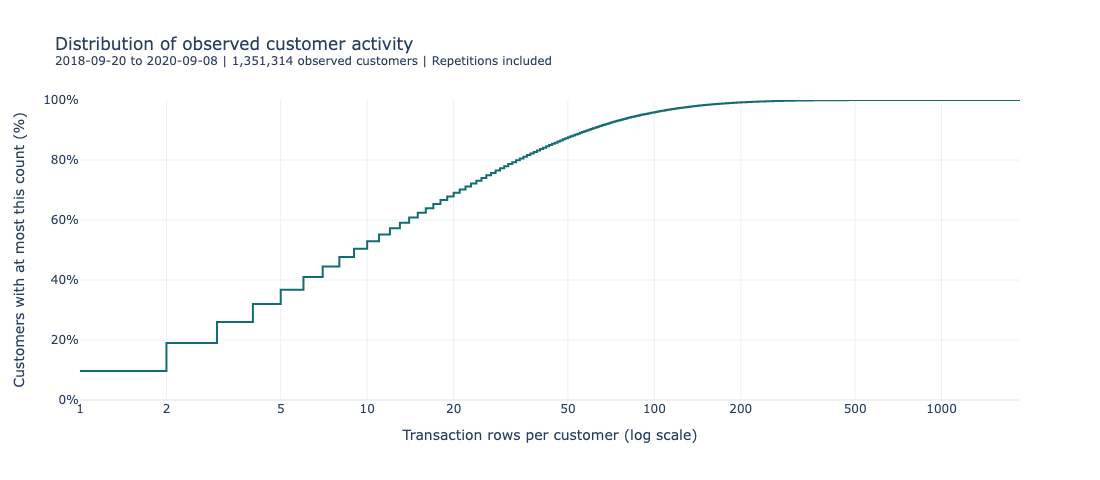

In [13]:
fig = px.line(
    activity_distribution,
    x="transaction_rows",
    y="cumulative_customer_pct",
    line_shape="hv",
    log_x=True,
    color_discrete_sequence=["#146C70"],
    template="plotly_white",
    hover_data={
        "customers": ":,",
        "cumulative_customer_pct": ":.2f",
    },
    labels={
        "transaction_rows": (
            "Transaction rows per customer (log scale)"
        ),
        "cumulative_customer_pct": (
            "Customers with at most this count (%)"
        ),
        "customers": "Customers at this exact count",
    },
    title=(
        "Distribution of observed customer activity"
        f"<br><sup>{EDA_START.date()} to "
        f"{(EDA_END_EXCLUSIVE - pd.Timedelta(days=1)).date()}"
        f" | {observed_customers:,} observed customers"
        " | Repetitions included</sup>"
    ),
)

fig.update_layout(
    width=1100,
    height=480,
    showlegend=False,
)

fig.update_yaxes(
    range=[0, 100],
    ticksuffix="%",
)

activity_ticks = [
    1, 2, 5, 10, 20, 50, 100, 200, 500, 1000
]

fig.update_xaxes(
    tickmode="array",
    tickvals=activity_ticks,
    ticktext=[str(value) for value in activity_ticks],
)

fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

### 4.4. Interpretation Scope

This analysis describes transaction-row frequency among customers
with observed history in the declared interval.

It does not yet distinguish:
- several rows on one purchase day from purchases across many days;
- repeated purchases from distinct purchased articles;
- recent activity from older activity.

Low observed frequency may also reflect a short observed history.
These distinctions are addressed by the following customer analyses.

### 4.5. Frequency Findings

The analysis includes 1,351,314 observed customers and reconciles
with 31,292,772 retained transaction rows.

Exactly one transaction row is observed for 130,217 customers,
representing approximately 9.636% of the population.

Approximately 50.4% of customers have at most nine transaction rows,
and 90.1% have at most 59 rows.

These results describe heterogeneous observed transaction volumes.
They do not yet distinguish recent activity, repeated purchase days
or distinct purchased articles.

### 4.6. Observed Purchase Dates

Compute the first and last observed purchase dates for each customer
within the declared EDA interval.

Within each chunk, aggregate minimum and maximum dates by customer.
Combine these bounds across chunks using the earliest minimum and
the latest maximum.

First observed purchase dates do not establish customer registration
or lifetime purchase history.

In [14]:
customer_date_bounds = {}
customer_date_rows_scanned = 0

with closing(
    iter_eda_chunks(
        columns=["t_dat", "customer_id"]
    )
) as eda_chunks:
    for chunk_number, chunk in enumerate(
        eda_chunks,
        start=1,
    ):
        dated_chunk = chunk.assign(
            t_dat=pd.to_datetime(
                chunk["t_dat"],
                format="%Y-%m-%d",
                errors="raise",
            )
        )

        chunk_bounds = (
            dated_chunk
            .groupby("customer_id", sort=False)
            .agg(
                first_observed_purchase=("t_dat", "min"),
                last_observed_purchase=("t_dat", "max"),
            )
        )

        for customer_id, first_date, last_date in (
            chunk_bounds.itertuples(name=None)
        ):
            previous_bounds = customer_date_bounds.get(
                customer_id
            )

            if previous_bounds is None:
                customer_date_bounds[customer_id] = (
                    first_date,
                    last_date,
                )
            else:
                customer_date_bounds[customer_id] = (
                    min(previous_bounds[0], first_date),
                    max(previous_bounds[1], last_date),
                )

        customer_date_rows_scanned += len(chunk)

        if chunk_number % 50 == 0:
            print(
                f"{customer_date_rows_scanned:,} "
                "eligible transaction rows processed",
                flush=True,
            )

if customer_date_rows_scanned != eda_transaction_rows:
    raise ValueError(
        "Customer date scan differs from the EDA scope."
    )

print(
    f"Completed: {len(customer_date_bounds):,} "
    "customer date bounds."
)

5,000,000 eligible transaction rows processed
10,000,000 eligible transaction rows processed
15,000,000 eligible transaction rows processed
20,000,000 eligible transaction rows processed
25,000,000 eligible transaction rows processed
30,000,000 eligible transaction rows processed
Completed: 1,351,314 customer date bounds.


In [15]:
customer_date_table = (
    pd.DataFrame.from_dict(
        customer_date_bounds,
        orient="index",
        columns=[
            "first_observed_purchase",
            "last_observed_purchase",
        ],
    )
    .rename_axis("customer_id")
    .reset_index()
)

del customer_date_bounds

customer_date_table["customer_id"] = (
    customer_date_table["customer_id"].astype("string")
)

if len(customer_date_table) != observed_customers:
    raise ValueError(
        "Customer date bounds differ from "
        "the observed customer population."
    )

customer_temporal_activity = customer_activity.merge(
    customer_date_table,
    on="customer_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

if not customer_temporal_activity["_merge"].eq("both").all():
    raise ValueError(
        "Some observed customers have no matching date bounds."
    )

customer_temporal_activity = (
    customer_temporal_activity.drop(columns="_merge")
)

valid_date_bounds = (
    customer_temporal_activity["first_observed_purchase"]
    .ge(EDA_START)
    & customer_temporal_activity["last_observed_purchase"]
    .lt(EDA_END_EXCLUSIVE)
    & customer_temporal_activity["first_observed_purchase"]
    .le(
        customer_temporal_activity[
            "last_observed_purchase"
        ]
    )
)

if not valid_date_bounds.all():
    raise ValueError(
        "Customer purchase-date bounds are inconsistent."
    )

print(
    f"Validated date bounds for "
    f"{len(customer_temporal_activity):,} customers."
)

Validated date bounds for 1,351,314 customers.


### 4.7. Recency and Observed Purchase Span

All durations use the EDA cutoff as the reference date.

- Recency: cutoff minus last observed purchase.
- Days since first observed purchase: cutoff minus first observed purchase.
- Observed purchase span: last minus first observed purchase.

Since transactions precede the cutoff, recency is at least one day.

A zero purchase span means that first and last observed purchases
occur on the same date. It does not imply exactly one transaction row.

In [16]:
customer_temporal_activity["recency_days"] = (
    EDA_END_EXCLUSIVE
    - customer_temporal_activity[
        "last_observed_purchase"
    ]
).dt.days

customer_temporal_activity[
    "days_since_first_observed_purchase"
] = (
    EDA_END_EXCLUSIVE
    - customer_temporal_activity[
        "first_observed_purchase"
    ]
).dt.days

customer_temporal_activity[
    "observed_purchase_span_days"
] = (
    customer_temporal_activity[
        "last_observed_purchase"
    ]
    - customer_temporal_activity[
        "first_observed_purchase"
    ]
).dt.days

In [17]:
temporal_summary = (
    customer_temporal_activity[
        [
            "recency_days",
            "days_since_first_observed_purchase",
            "observed_purchase_span_days",
        ]
    ]
    .agg(["min", "median", "max"])
    .T
)

temporal_summary

,min,median,max
recency_days,1.0,149.0,720.0
days_since_first_observed_purchase,1.0,574.0,720.0
observed_purchase_span_days,0.0,203.0,719.0


### 4.8. Recency Distribution

The cumulative distribution reports the percentage of observed
customers whose last purchase occurred at most x days before
the EDA cutoff.

Each observed customer contributes equally.
The horizontal axis uses calendar days on a linear scale.

Recency describes observed purchase timing. It does not establish
churn or future purchase intent.

In [18]:
recency_distribution = (
    customer_temporal_activity["recency_days"]
    .value_counts()
    .sort_index()
    .rename_axis("recency_days")
    .reset_index(name="customers")
)

recency_distribution["cumulative_customer_pct"] = (
    100
    * recency_distribution["customers"].cumsum()
    / observed_customers
)

if int(
    recency_distribution["customers"].sum()
) != observed_customers:
    raise ValueError(
        "Recency distribution differs from "
        "the observed customer population."
    )

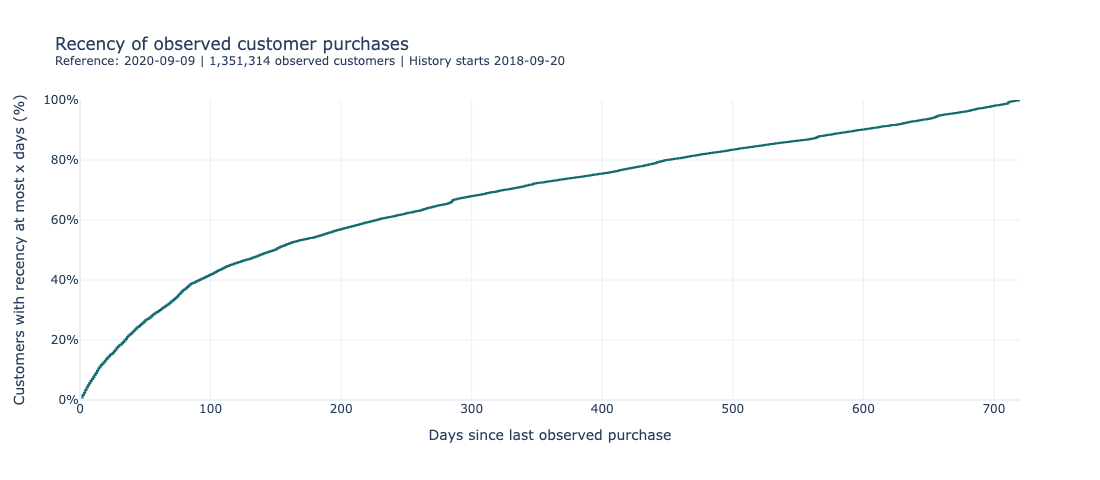

In [19]:
fig = px.line(
    recency_distribution,
    x="recency_days",
    y="cumulative_customer_pct",
    line_shape="hv",
    color_discrete_sequence=["#146C70"],
    template="plotly_white",
    hover_data={
        "customers": ":,",
        "cumulative_customer_pct": ":.2f",
    },
    labels={
        "recency_days": "Days since last observed purchase",
        "cumulative_customer_pct": (
            "Customers with recency at most x days (%)"
        ),
        "customers": "Customers at this exact recency",
    },
    title=(
        "Recency of observed customer purchases"
        f"<br><sup>Reference: {EDA_END_EXCLUSIVE.date()}"
        f" | {observed_customers:,} observed customers"
        f" | History starts {EDA_START.date()}</sup>"
    ),
)

fig.update_layout(
    width=1100,
    height=480,
    showlegend=False,
)

fig.update_xaxes(rangemode="tozero")
fig.update_yaxes(range=[0, 100], ticksuffix="%")

fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

### 4.9. Temporal Findings

Customer purchase-date bounds cover the same 1,351,314 observed
customers as the frequency analysis.

Median recency is 149 days.
The median time since first observed purchase is 574 days,
and the median observed purchase span is 203 days.

These marginal medians are not additive.

Approximately 17.39% of observed customers have a purchase within
the final 28 days before the EDA cutoff.

Observed recency does not establish churn, registration dates
or future purchase intent.

### 4.10. Exact Purchase-Day Counts

A purchase day is a distinct transaction date observed for a customer
within [EDA_START, EDA_END_EXCLUSIVE).

Transactions are grouped globally by customer and calendar date.
Each resulting group represents one observed customer–day pair.

The group retains its transaction-row count.
These counts are then summed by customer and compared with the
previous pandas frequency results.

Grouping creates an analytical summary. Source transaction rows
remain unchanged.

DuckDB uses a temporary local working database and spill directory.
Only customer-level summaries are returned to pandas.

In [20]:
customer_day_groups_query = """
CREATE TABLE customer_day_groups AS
SELECT
    customer_id,
    CAST(t_dat AS DATE) AS purchase_date,
    COUNT(*)::BIGINT AS transaction_rows
FROM read_csv(
    ?,
    header = true,
    delim = ',',
    all_varchar = true,
    force_not_null = ['t_dat', 'customer_id'],
    ignore_errors = false
)
WHERE CAST(t_dat AS DATE) >= ?
  AND CAST(t_dat AS DATE) < ?
GROUP BY
    customer_id,
    CAST(t_dat AS DATE)
"""

In [21]:
query_parameters = [
    str(RAW_DATA_DIRECTORY / "transactions_train.csv"),
    EDA_START.date(),
    EDA_END_EXCLUSIVE.date(),
]

with TemporaryDirectory(
    prefix="atelier-ai-distinct-"
) as working_directory:
    working_path = Path(working_directory)

    with duckdb.connect(
        database=str(working_path / "working.duckdb"),
        config={
            "memory_limit": "1GB",
            "threads": 2,
            "temp_directory": str(
                working_path / "spill"
            ),
            "preserve_insertion_order": False,
        },
    ) as connection:
        print(
            "Grouping eligible customer-day pairs...",
            flush=True,
        )

        connection.execute(
            customer_day_groups_query,
            query_parameters,
        )

        print(
            "Counting purchase days per customer...",
            flush=True,
        )

        customer_day_counts = connection.execute(
            """
            SELECT
                customer_id,
                COUNT(*)::BIGINT AS purchase_days,
                SUM(transaction_rows)::BIGINT
                    AS transaction_rows_check
            FROM customer_day_groups
            GROUP BY customer_id
            """
        ).df()

print(
    f"Completed: {len(customer_day_counts):,} "
    "customer purchase-day counts."
)

Grouping eligible customer-day pairs...
Counting purchase days per customer...
Completed: 1,351,314 customer purchase-day counts.


### 4.11. Purchase-Day Reconciliation

Match the purchase-day counts to the existing temporal customer table
using a validated one-to-one join.

For every customer:
- transaction-row counts must match the pandas calculation;
- at least one purchase day must be observed;
- purchase days cannot exceed transaction rows;
- purchase days cannot exceed the observed purchase span plus one.

In [22]:
customer_day_counts["customer_id"] = (
    customer_day_counts["customer_id"].astype("string")
)

if len(customer_day_counts) != observed_customers:
    raise ValueError(
        "Purchase-day counts differ from "
        "the observed customer population."
    )

customer_profile = customer_temporal_activity.merge(
    customer_day_counts,
    on="customer_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

if not customer_profile["_merge"].eq("both").all():
    raise ValueError(
        "Some observed customers have no purchase-day count."
    )

purchase_day_checks = pd.Series(
    {
        "transaction_counts_match_pandas": bool(
            customer_profile["transaction_rows_check"]
            .eq(customer_profile["transaction_rows"])
            .all()
        ),
        "at_least_one_purchase_day": bool(
            customer_profile["purchase_days"].ge(1).all()
        ),
        "purchase_days_not_above_rows": bool(
            customer_profile["purchase_days"]
            .le(customer_profile["transaction_rows"])
            .all()
        ),
        "purchase_days_fit_observed_span": bool(
            customer_profile["purchase_days"]
            .le(
                customer_profile[
                    "observed_purchase_span_days"
                ] + 1
            )
            .all()
        ),
    },
    name="passed",
)

if not purchase_day_checks.all():
    failed_checks = purchase_day_checks.index[
        ~purchase_day_checks
    ].tolist()

    raise ValueError(
        f"Purchase-day checks failed: {failed_checks}"
    )

customer_profile = customer_profile.drop(
    columns=["_merge", "transaction_rows_check"]
)

purchase_day_checks.to_frame()

,passed
transaction_counts_match_pandas,True
at_least_one_purchase_day,True
purchase_days_not_above_rows,True
purchase_days_fit_observed_span,True


In [23]:
single_day_customers = int(
    customer_profile["purchase_days"].eq(1).sum()
)

purchase_day_summary = pd.Series(
    {
        "observed_customers": len(customer_profile),
        "distinct_customer_day_pairs": int(
            customer_profile["purchase_days"].sum()
        ),
        "customers_with_one_purchase_day": (
            single_day_customers
        ),
        "customers_with_one_purchase_day_pct": round(
            100 * single_day_customers / observed_customers,
            3,
        ),
    },
    name="value",
    dtype="object",
).rename_axis("measure").to_frame()

purchase_day_summary

,value
measure,
observed_customers,1351314
distinct_customer_day_pairs,8921876
customers_with_one_purchase_day,444424
customers_with_one_purchase_day_pct,32.888


### 4.12. Purchase-Day Distribution

The cumulative distribution reports the percentage of observed
customers with at most x distinct purchase days.

Each customer contributes equally.
Multiple transaction rows on the same date count as one purchase day.

The horizontal axis uses a logarithmic scale.

In [24]:
purchase_day_distribution = (
    customer_profile["purchase_days"]
    .value_counts()
    .sort_index()
    .rename_axis("purchase_days")
    .reset_index(name="customers")
)

purchase_day_distribution[
    "cumulative_customer_pct"
] = (
    100
    * purchase_day_distribution["customers"].cumsum()
    / observed_customers
)

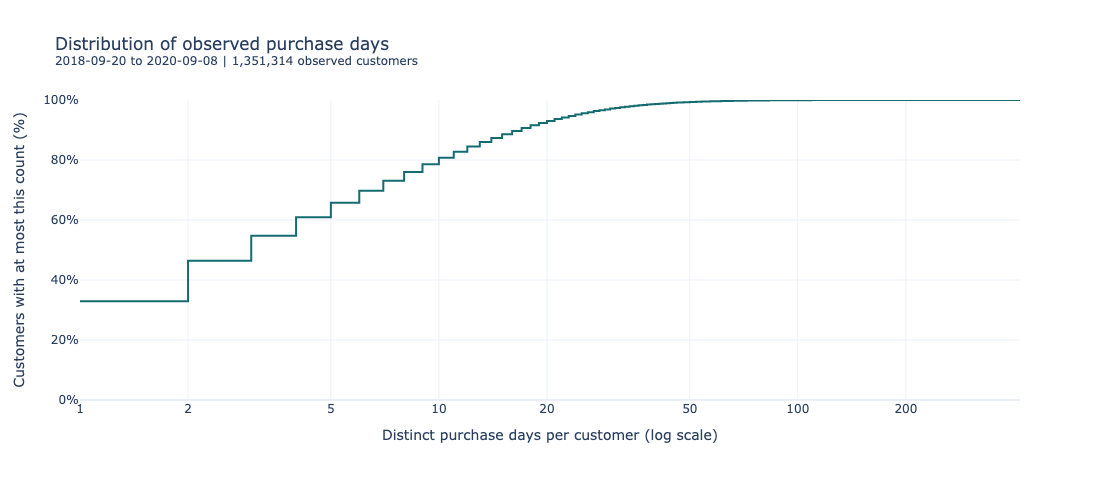

In [25]:
fig = px.line(
    purchase_day_distribution,
    x="purchase_days",
    y="cumulative_customer_pct",
    line_shape="hv",
    log_x=True,
    color_discrete_sequence=["#146C70"],
    template="plotly_white",
    labels={
        "purchase_days": (
            "Distinct purchase days per customer (log scale)"
        ),
        "cumulative_customer_pct": (
            "Customers with at most this count (%)"
        ),
    },
    title=(
        "Distribution of observed purchase days"
        f"<br><sup>{EDA_START.date()} to "
        f"{(EDA_END_EXCLUSIVE - pd.Timedelta(days=1)).date()}"
        f" | {observed_customers:,} observed customers</sup>"
    ),
)

purchase_day_ticks = [
    1, 2, 5, 10, 20, 50, 100, 200, 500
]

fig.update_xaxes(
    tickmode="array",
    tickvals=purchase_day_ticks,
    ticktext=[
        str(value) for value in purchase_day_ticks
    ],
)

fig.update_yaxes(range=[0, 100], ticksuffix="%")
fig.update_layout(width=1100, height=480)

fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

### 4.13. Purchase-Day Findings

The pre-validation history contains 8,921,876 distinct customer–date
pairs across 1,351,314 observed customers.

A total of 444,424 customers (32.89%) have purchases recorded on
exactly one date. This exceeds the 130,217 customers with exactly
one transaction row: 314,207 customers have multiple transaction
rows recorded on a single date.

Transaction-row counts and distinct purchase-day counts therefore
capture different aspects of observed activity. A purchase date
does not identify an order, basket or shopping session.

All measurements describe the retained observation window rather
than each customer's complete purchasing history.

### 4.14. Exact Distinct-Article Counts

For each observed customer, count distinct article IDs purchased
during the pre-validation history.

Each customer–article pair contributes once to this measure,
regardless of its transaction-row count or number of purchase dates.
Article IDs remain strings to preserve leading zeros.

The calculation first groups eligible transactions by customer and
article, then counts the resulting pairs per customer. Transaction-row
counts are retained within each pair for reconciliation with pandas.

In [26]:
customer_article_groups_query = """
CREATE TABLE customer_article_groups AS
SELECT
    customer_id,
    article_id,
    COUNT(*)::BIGINT AS transaction_rows
FROM read_csv(
    ?,
    header = true,
    delim = ',',
    all_varchar = true,
    force_not_null = ['t_dat', 'customer_id', 'article_id'],
    ignore_errors = false
)
WHERE CAST(t_dat AS DATE) >= ?
  AND CAST(t_dat AS DATE) < ?
GROUP BY
    customer_id,
    article_id
"""

In [27]:
article_query_parameters = [
    str(RAW_DATA_DIRECTORY / "transactions_train.csv"),
    EDA_START.date(),
    EDA_END_EXCLUSIVE.date(),
]

with TemporaryDirectory(
    prefix="atelier-ai-articles-"
) as working_directory:
    working_path = Path(working_directory)

    with duckdb.connect(
        database=str(working_path / "working.duckdb"),
        config={
            "memory_limit": "1GB",
            "threads": 2,
            "temp_directory": str(
                working_path / "spill"
            ),
            "preserve_insertion_order": False,
        },
    ) as connection:
        print(
            "Grouping eligible customer-article pairs...",
            flush=True,
        )

        connection.execute(
            customer_article_groups_query,
            article_query_parameters,
        )

        print(
            "Counting distinct articles per customer...",
            flush=True,
        )

        customer_article_counts = connection.execute(
            """
            SELECT
                customer_id,
                COUNT(*)::BIGINT AS distinct_articles,
                SUM(transaction_rows)::BIGINT
                    AS transaction_rows_check
            FROM customer_article_groups
            GROUP BY customer_id
            """
        ).df()

print(
    f"Completed: {len(customer_article_counts):,} "
    "customer distinct-article counts."
)

Grouping eligible customer-article pairs...
Counting distinct articles per customer...
Completed: 1,351,314 customer distinct-article counts.


### 4.15. Distinct-Article Reconciliation

Attach distinct-article counts to the existing customer profile using
a one-to-one merge.

Require complete customer coverage, agreement with pandas transaction
counts, and a distinct-article count between one and the customer's
transaction-row count.

In [28]:
customer_article_counts["customer_id"] = (
    customer_article_counts["customer_id"].astype("string")
)

if len(customer_article_counts) != observed_customers:
    raise ValueError(
        "Distinct-article counts differ from "
        "the observed customer population."
    )

customer_profile_complete = customer_profile.merge(
    customer_article_counts,
    on="customer_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

if not customer_profile_complete["_merge"].eq("both").all():
    raise ValueError(
        "Some observed customers have no distinct-article count."
    )

distinct_article_checks = pd.Series(
    {
        "transaction_counts_match_pandas": bool(
            customer_profile_complete["transaction_rows_check"]
            .eq(customer_profile_complete["transaction_rows"])
            .all()
        ),
        "at_least_one_distinct_article": bool(
            customer_profile_complete["distinct_articles"]
            .ge(1)
            .all()
        ),
        "distinct_articles_not_above_rows": bool(
            customer_profile_complete["distinct_articles"]
            .le(customer_profile_complete["transaction_rows"])
            .all()
        ),
    },
    name="passed",
)

if not distinct_article_checks.all():
    failed_checks = distinct_article_checks.index[
        ~distinct_article_checks
    ].tolist()

    raise ValueError(
        f"Distinct-article checks failed: {failed_checks}"
    )

customer_profile_complete = customer_profile_complete.drop(
    columns=["_merge", "transaction_rows_check"]
)

distinct_article_checks.to_frame()

,passed
transaction_counts_match_pandas,True
at_least_one_distinct_article,True
distinct_articles_not_above_rows,True


In [29]:
single_article_customers = int(
    customer_profile_complete["distinct_articles"].eq(1).sum()
)

distinct_article_summary = pd.Series(
    {
        "observed_customers": len(customer_profile_complete),
        "distinct_customer_article_pairs": int(
            customer_profile_complete["distinct_articles"].sum()
        ),
        "customers_with_one_distinct_article": (
            single_article_customers
        ),
        "customers_with_one_distinct_article_pct": round(
            100 * single_article_customers / observed_customers,
            3,
        ),
        "median_distinct_articles_per_customer": (
            customer_profile_complete["distinct_articles"].median()
        ),
    },
    name="value",
    dtype="object",
).rename_axis("measure").to_frame()

distinct_article_summary

,value
measure,
observed_customers,1351314
distinct_customer_article_pairs,26882193
customers_with_one_distinct_article,153423
customers_with_one_distinct_article_pct,11.354
median_distinct_articles_per_customer,8.0


### 4.16. Distinct-Article Distribution

The cumulative distribution shows the percentage of observed customers
with at most a given number of distinct purchased articles.

The horizontal axis uses a logarithmic scale. Each customer contributes
equally to the distribution, regardless of transaction-row count.

In [30]:
distinct_article_distribution = (
    customer_profile_complete["distinct_articles"]
    .value_counts()
    .sort_index()
    .rename_axis("distinct_articles")
    .reset_index(name="customers")
)

distinct_article_distribution[
    "cumulative_customer_pct"
] = (
    100
    * distinct_article_distribution["customers"].cumsum()
    / observed_customers
)

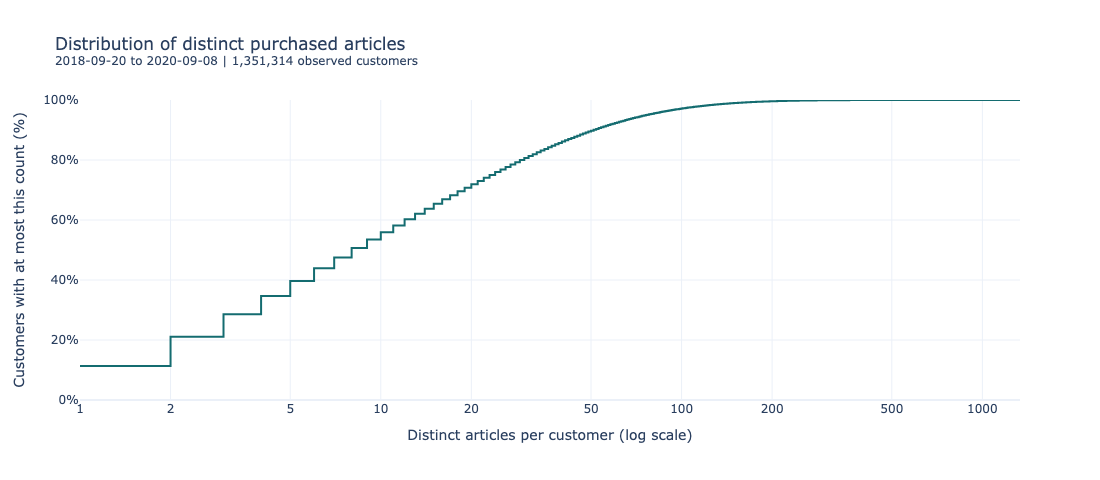

In [31]:
fig = px.line(
    distinct_article_distribution,
    x="distinct_articles",
    y="cumulative_customer_pct",
    line_shape="hv",
    log_x=True,
    color_discrete_sequence=["#146C70"],
    template="plotly_white",
    hover_data={
        "customers": ":,",
        "cumulative_customer_pct": ":.2f",
    },
    labels={
        "distinct_articles": (
            "Distinct articles per customer (log scale)"
        ),
        "customers": "Customers at this count",
        "cumulative_customer_pct": (
            "Customers with at most this count (%)"
        ),
    },
    title=(
        "Distribution of distinct purchased articles"
        f"<br><sup>{EDA_START.date()} to "
        f"{(EDA_END_EXCLUSIVE - pd.Timedelta(days=1)).date()}"
        f" | {observed_customers:,} observed customers</sup>"
    ),
)

distinct_article_ticks = [
    1, 2, 5, 10, 20, 50, 100, 200, 500, 1000
]

fig.update_xaxes(
    tickmode="array",
    tickvals=distinct_article_ticks,
    ticktext=[
        str(value) for value in distinct_article_ticks
    ],
)

fig.update_yaxes(range=[0, 100], ticksuffix="%")
fig.update_layout(width=1100, height=480)

fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

### 4.17. Distinct-Article Findings

The pre-validation history contains 26,882,193 distinct
customer–article pairs across 1,351,314 observed customers.

The median customer has eight distinct purchased articles.
Exactly one distinct article is observed for 153,423 customers,
representing approximately 11.35% of the observed population.

These measurements describe article breadth within the retained
history. They do not establish product exposure, category preferences
or complete lifetime purchasing behavior.

Several transaction rows for the same customer–article pair do not
by themselves establish purchases on different dates.

### 4.18. Descriptive Customer Profiles

Compare customers along two observed dimensions:

- one purchase date versus multiple purchase dates;
- recency of 1–28 days versus more than 28 days.

The 28-day threshold is a descriptive reference.
Group membership uses only the retained pre-validation history.

These groups do not establish customer acquisition, loyalty or churn.
Differences in observed history length must also be considered.

In [32]:
comparison_columns = [
    "transaction_rows",
    "purchase_days",
    "distinct_articles",
    "recency_days",
    "days_since_first_observed_purchase",
]

profile_comparison_input = customer_profile_complete[
    comparison_columns
].copy()

if len(profile_comparison_input) != observed_customers:
    raise ValueError(
        "Profile comparison differs from "
        "the observed customer population."
    )

if profile_comparison_input.isna().any().any():
    raise ValueError(
        "Profile comparison measures must be complete."
    )

purchase_day_order = [
    "One purchase day",
    "Multiple purchase days",
]

recency_order = [
    f"Recency 1-{RECENT_ACTIVITY_DAYS} days",
    f"Recency >{RECENT_ACTIVITY_DAYS} days",
]

profile_comparison_input["purchase_day_group"] = (
    pd.Categorical(
        profile_comparison_input["purchase_days"]
        .eq(1)
        .map(
            {
                True: purchase_day_order[0],
                False: purchase_day_order[1],
            }
        ),
        categories=purchase_day_order,
        ordered=True,
    )
)

profile_comparison_input["recency_group"] = (
    pd.Categorical(
        profile_comparison_input["recency_days"]
        .le(RECENT_ACTIVITY_DAYS)
        .map(
            {
                True: recency_order[0],
                False: recency_order[1],
            }
        ),
        categories=recency_order,
        ordered=True,
    )
)

### 4.19. Customer-Profile Aggregates

For each observed combination, report customer counts,
transaction-row totals and median customer-level measures.

Customer shares use all observed customers as the denominator.
Transaction-row shares use all retained transaction rows.

Days since first observed purchase describe observed history length.
They do not establish registration dates or customer tenure.

In [33]:
profile_summary = (
    profile_comparison_input
    .groupby(
        ["purchase_day_group", "recency_group"],
        observed=True,
        sort=True,
    )
    .agg(
        customers=("transaction_rows", "size"),
        transaction_rows=("transaction_rows", "sum"),
        total_purchase_days=("purchase_days", "sum"),
        customer_article_pairs=("distinct_articles", "sum"),
        median_transaction_rows=("transaction_rows", "median"),
        median_purchase_days=("purchase_days", "median"),
        median_distinct_articles=("distinct_articles", "median"),
        median_recency_days=("recency_days", "median"),
        median_days_since_first_observed_purchase=(
            "days_since_first_observed_purchase",
            "median",
        ),
    )
    .reset_index()
)

profile_summary["customer_pct"] = (
    100 * profile_summary["customers"] / observed_customers
)

profile_summary["transaction_row_pct"] = (
    100
    * profile_summary["transaction_rows"]
    / eda_transaction_rows
)

In [34]:
profile_comparison_checks = pd.Series(
    {
        "customer_population_preserved": (
            int(profile_summary["customers"].sum())
            == observed_customers
        ),
        "transaction_rows_preserved": (
            int(profile_summary["transaction_rows"].sum())
            == eda_transaction_rows
        ),
        "purchase_day_pairs_preserved": (
            int(profile_summary["total_purchase_days"].sum())
            == int(customer_profile_complete["purchase_days"].sum())
        ),
        "customer_article_pairs_preserved": (
            int(profile_summary["customer_article_pairs"].sum())
            == int(
                customer_profile_complete["distinct_articles"].sum()
            )
        ),
    },
    name="passed",
)

if not profile_comparison_checks.all():
    failed_checks = profile_comparison_checks.index[
        ~profile_comparison_checks
    ].tolist()

    raise ValueError(
        f"Profile comparison checks failed: {failed_checks}"
    )

profile_comparison_checks.to_frame()

,passed
customer_population_preserved,True
transaction_rows_preserved,True
purchase_day_pairs_preserved,True
customer_article_pairs_preserved,True


### 4.20. Customer-Profile Comparison Tables

The population table compares each group's share of observed
customers with its share of retained transaction rows.

The median table describes customer-level activity within each group.
Group medians are not additive.

Differences remain descriptive. Observed history length is reported
for context and does not statistically adjust the comparisons.

In [35]:
profile_population_table = (
    profile_summary
    .set_index(["purchase_day_group", "recency_group"])
    [
        [
            "customers",
            "customer_pct",
            "transaction_rows",
            "transaction_row_pct",
        ]
    ]
    .rename(
        columns={
            "customers": "Customers",
            "customer_pct": "Customers (%)",
            "transaction_rows": "Transaction rows",
            "transaction_row_pct": "Transaction rows (%)",
        }
    )
    .round(2)
)

profile_population_table

Customers  Customers (%)  \
purchase_day_group     recency_group                                 
One purchase day       Recency 1-28 days      18662           1.38   
                       Recency >28 days      425762          31.51   
Multiple purchase days Recency 1-28 days     216327          16.01   
                       Recency >28 days      690563          51.10   

                                          Transaction rows  \
purchase_day_group     recency_group                         
One purchase day       Recency 1-28 days             60040   
                       Recency >28 days            1481484   
Multiple purchase days Recency 1-28 days          12464258   
                       Recency >28 days           17286990   

                                          Transaction rows (%)  
purchase_day_group     recency_group                            
One purchase day       Recency 1-28 days                  0.19  
                       Recency >28 days                   4.73  
Multiple purchase days Recency 1-28 days                 39.83  
                       Recency >28 days                  55.24

In [36]:
profile_measure_table = (
    profile_summary
    .set_index(["purchase_day_group", "recency_group"])
    [
        [
            "median_transaction_rows",
            "median_purchase_days",
            "median_distinct_articles",
            "median_recency_days",
            "median_days_since_first_observed_purchase",
        ]
    ]
    .rename(
        columns={
            "median_transaction_rows": "Rows (median)",
            "median_purchase_days": "Purchase days (median)",
            "median_distinct_articles": "Articles (median)",
            "median_recency_days": "Recency (days, median)",
            "median_days_since_first_observed_purchase": (
                "Since first observed (days, median)"
            ),
        }
    )
    .round(1)
)

profile_measure_table

Rows (median)  \
purchase_day_group     recency_group                      
One purchase day       Recency 1-28 days            2.0   
                       Recency >28 days             2.0   
Multiple purchase days Recency 1-28 days           37.0   
                       Recency >28 days            15.0   

                                          Purchase days (median)  \
purchase_day_group     recency_group                               
One purchase day       Recency 1-28 days                     1.0   
                       Recency >28 days                      1.0   
Multiple purchase days Recency 1-28 days                    12.0   
                       Recency >28 days                      5.0   

                                          Articles (median)  \
purchase_day_group     recency_group                          
One purchase day       Recency 1-28 days                2.0   
                       Recency >28 days                 2.0   
Multiple purchase days Recency 1-28 days               33.0   
                       Recency >28 days                13.0   

                                          Recency (days, median)  \
purchase_day_group     recency_group                               
One purchase day       Recency 1-28 days                    13.0   
                       Recency >28 days                    415.0   
Multiple purchase days Recency 1-28 days                    12.0   
                       Recency >28 days                    136.0   

                                          Since first observed (days, median)  
purchase_day_group     recency_group                                           
One purchase day       Recency 1-28 days                                 13.0  
                       Recency >28 days                                 415.0  
Multiple purchase days Recency 1-28 days                                658.0  
                       Recency >28 days                                 624.0

### 4.21. Customer Shares and Historical Transaction Shares

Compare each group's share of all observed customers with its share
of all retained transaction rows.

Recency determines customer membership. Transaction-row counts cover
the full retained history, including purchases before the final
28-day window.

The two percentages use different denominators:
1,351,314 observed customers and 31,292,772 retained transaction rows.

In [37]:
profile_chart_data = profile_summary.copy()

profile_chart_data["profile_label"] = (
    profile_chart_data["purchase_day_group"].astype("string")
    + "<br>"
    + profile_chart_data["recency_group"].astype("string")
)

profile_order = [
    f"{purchase_day_group}<br>{recency_group}"
    for purchase_day_group in purchase_day_order
    for recency_group in recency_order
]

profile_share_data = profile_chart_data.melt(
    id_vars=[
        "profile_label",
        "customers",
        "transaction_rows",
    ],
    value_vars=[
        "customer_pct",
        "transaction_row_pct",
    ],
    var_name="measure",
    value_name="share_pct",
)

profile_share_data["measure"] = (
    profile_share_data["measure"].map(
        {
            "customer_pct": "Observed customers",
            "transaction_row_pct": "Transaction rows",
        }
    )
)

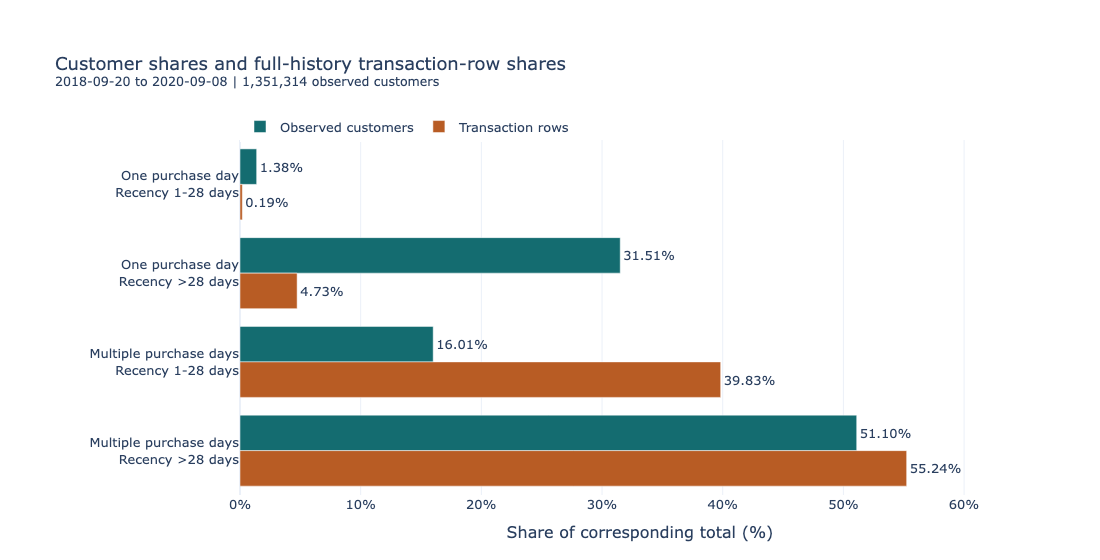

In [38]:
fig = px.bar(
    profile_share_data,
    x="share_pct",
    y="profile_label",
    color="measure",
    orientation="h",
    barmode="group",
    text="share_pct",
    category_orders={
        "measure": [
            "Observed customers",
            "Transaction rows",
        ],
    },
    color_discrete_map={
        "Observed customers": "#146C70",
        "Transaction rows": "#B85C24",
    },
    hover_data={
        "customers": ":,",
        "transaction_rows": ":,",
        "share_pct": ":.2f",
    },
    labels={
        "share_pct": "Share of corresponding total (%)",
        "profile_label": "Customer profile",
        "measure": "Measure",
        "customers": "Customers in group",
        "transaction_rows": "Full-history rows in group",
    },
    template="plotly_white",
    title=(
        "Customer shares and full-history transaction-row shares"
        f"<br><sup>{EDA_START.date()} to "
        f"{(EDA_END_EXCLUSIVE - pd.Timedelta(days=1)).date()}"
        f" | {observed_customers:,} observed customers</sup>"
    ),
)

fig.update_traces(
    texttemplate="%{x:.2f}%",
    textposition="outside",
    cliponaxis=False,
)

fig.update_yaxes(
    title_text=None,
    categoryorder="array",
    categoryarray=profile_order,
    autorange="reversed",
)

fig.update_xaxes(
    range=[
        0,
        float(profile_share_data["share_pct"].max()) * 1.2,
    ],
    ticksuffix="%",
)

fig.update_layout(
    width=1100,
    height=560,
    font={"size": 13},
    legend_title_text=None,
    legend={
        "orientation": "h",
        "y": 1.08,
        "x": 0,
    },
    margin={"l": 240, "r": 60, "t": 140, "b": 65},
)

fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

### 4.22. Median Historical Activity by Customer Profile

Compare median transaction rows, purchase days and distinct articles
across the same customer groups.

Each panel reports a separate customer-level median over the full
retained history. Panels share the same numerical scale and profile
order.

Medians describe central values, not within-group dispersion.
The separate medians do not necessarily describe one actual customer.

In [39]:
median_measure_order = [
    "Transaction rows",
    "Purchase days",
    "Distinct articles",
]

profile_median_data = profile_chart_data.melt(
    id_vars=["profile_label", "customers"],
    value_vars=[
        "median_transaction_rows",
        "median_purchase_days",
        "median_distinct_articles",
    ],
    var_name="measure",
    value_name="median_value",
)

profile_median_data["measure"] = (
    profile_median_data["measure"].map(
        {
            "median_transaction_rows": "Transaction rows",
            "median_purchase_days": "Purchase days",
            "median_distinct_articles": "Distinct articles",
        }
    )
)

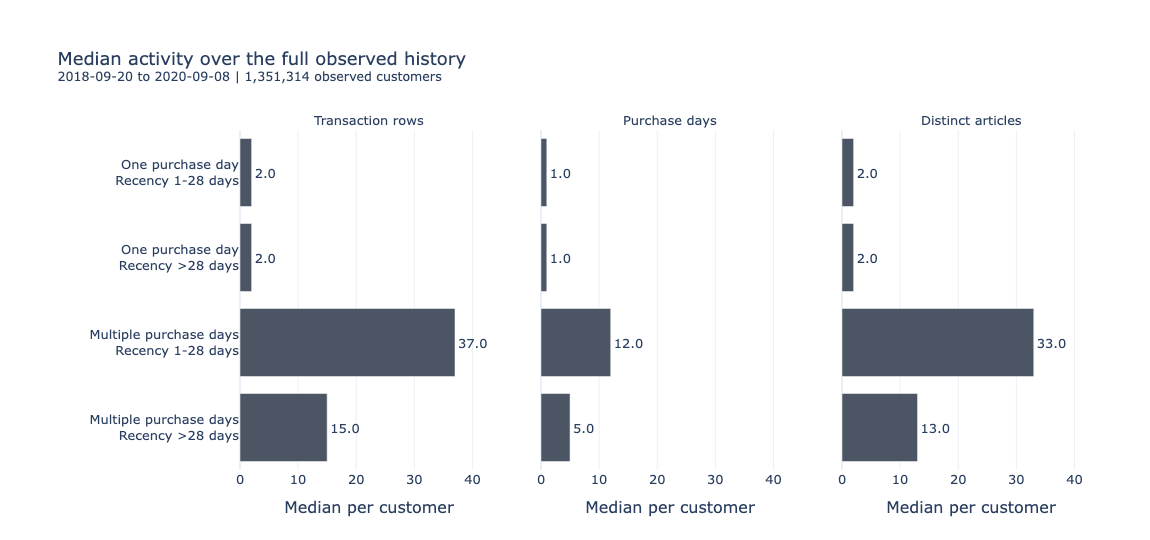

In [40]:
fig = px.bar(
    profile_median_data,
    x="median_value",
    y="profile_label",
    facet_col="measure",
    facet_col_spacing=0.05,
    orientation="h",
    text="median_value",
    category_orders={
        "measure": median_measure_order,
    },
    color_discrete_sequence=["#4B5563"],
    hover_data={
        "customers": ":,",
        "median_value": ":.1f",
    },
    labels={
        "median_value": "Median per customer",
        "profile_label": "Customer profile",
        "customers": "Customers in group",
    },
    template="plotly_white",
    title=(
        "Median activity over the full observed history"
        f"<br><sup>{EDA_START.date()} to "
        f"{(EDA_END_EXCLUSIVE - pd.Timedelta(days=1)).date()}"
        f" | {observed_customers:,} observed customers</sup>"
    ),
)

fig.update_traces(
    texttemplate="%{x:.1f}",
    textposition="outside",
    cliponaxis=False,
)

fig.update_yaxes(
    title_text=None,
    categoryorder="array",
    categoryarray=profile_order,
    autorange="reversed",
)

fig.update_xaxes(
    range=[
        0,
        float(profile_median_data["median_value"].max()) * 1.2,
    ],
    title_text="Median per customer",
)

for annotation in fig.layout.annotations:
    annotation.text = annotation.text.split("=", 1)[-1]

fig.update_layout(
    width=1150,
    height=540,
    font={"size": 13},
    showlegend=False,
    margin={"l": 240, "r": 50, "t": 130, "b": 70},
)

fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

### 4.23. Customer Activity Synthesis

The analysis covers 1,351,314 observed customers and 31,292,772
transaction rows within the pre-validation history.

**Activity measures capture different aspects of observed behavior.**

Exactly one transaction row is observed for approximately 9.64% of
customers, whereas approximately 32.89% have purchases on only one
date. The median number of distinct purchased articles is eight.

**Historical transaction volume is unevenly distributed across profiles.**

Customers with multiple purchase dates and recency of 1–28 days
represent 16.01% of observed customers and account for 39.83% of all
retained transaction rows. Their row contribution covers the full
history, not only the final 28 days.

Within the multiple-date population, the recent group has higher
median transaction rows (37 versus 15), purchase days (12 versus 5)
and distinct articles (33 versus 13) than the group with recency
above 28 days.

**Observed history length remains relevant to interpretation.**

Median days since first observed purchase are 658 and 624,
respectively, for these two multiple-date groups. Reporting history
length provides context but does not statistically adjust the
comparison.

These findings are descriptive. They do not establish loyalty, churn,
causal effects or future recommendation performance. Group medians
are calculated separately and do not necessarily describe one
actual customer.

## 5. Article Popularity

### 5.1. Measurement Scope

Build one row per article with at least one transaction in
[EDA_START, EDA_END_EXCLUSIVE).

Measure transaction rows, distinct observed buyers, and first and
last observed purchase dates.

Transaction-row counts and distinct-buyer counts describe different
aspects of observed popularity. Retained source repetitions remain
included in transaction-row counts.

First observed purchase dates do not establish article launch dates.
Articles without eligible transactions are outside this initial
behavioral table.

### 5.2. Exact Article–Customer Aggregation

Group eligible transactions globally by article and customer.

Each pair retains its transaction-row count and observed date bounds.
A second aggregation produces article-level measures:

- sum pair-level row counts;
- count pairs to obtain distinct buyers;
- combine date bounds using the earliest minimum and latest maximum.

Only the final article-level table is returned to pandas.

In [41]:
article_customer_groups_query = """
CREATE TABLE article_customer_groups AS
SELECT
    article_id,
    customer_id,
    COUNT(*)::BIGINT AS transaction_rows,
    MIN(CAST(t_dat AS DATE)) AS first_observed_purchase,
    MAX(CAST(t_dat AS DATE)) AS last_observed_purchase
FROM read_csv(
    ?,
    header = true,
    delim = ',',
    all_varchar = true,
    force_not_null = ['t_dat', 'customer_id', 'article_id'],
    ignore_errors = false
)
WHERE CAST(t_dat AS DATE) >= ?
  AND CAST(t_dat AS DATE) < ?
GROUP BY
    article_id,
    customer_id
"""

In [42]:
article_activity_parameters = [
    str(RAW_DATA_DIRECTORY / "transactions_train.csv"),
    EDA_START.date(),
    EDA_END_EXCLUSIVE.date(),
]

with TemporaryDirectory(
    prefix="atelier-ai-article-activity-"
) as working_directory:
    working_path = Path(working_directory)

    with duckdb.connect(
        database=str(working_path / "working.duckdb"),
        config={
            "memory_limit": "1GB",
            "threads": 2,
            "temp_directory": str(
                working_path / "spill"
            ),
            "preserve_insertion_order": False,
        },
    ) as connection:
        print(
            "Grouping eligible article-customer pairs...",
            flush=True,
        )

        connection.execute(
            article_customer_groups_query,
            article_activity_parameters,
        )

        print(
            "Building article-level activity...",
            flush=True,
        )

        article_activity = connection.execute(
            """
            SELECT
                article_id,
                SUM(transaction_rows)::BIGINT
                    AS transaction_rows,
                COUNT(*)::BIGINT AS observed_buyers,
                MIN(first_observed_purchase)
                    AS first_observed_purchase,
                MAX(last_observed_purchase)
                    AS last_observed_purchase
            FROM article_customer_groups
            GROUP BY article_id
            """
        ).df()

print(
    f"Completed: {len(article_activity):,} "
    "observed articles."
)

Grouping eligible article-customer pairs...
Building article-level activity...
Completed: 102,967 observed articles.


In [43]:
if article_activity.empty:
    raise ValueError(
        "No articles were observed in the EDA interval."
    )

article_activity["article_id"] = (
    article_activity["article_id"].astype("string")
)

for date_column in [
    "first_observed_purchase",
    "last_observed_purchase",
]:
    article_activity[date_column] = pd.to_datetime(
        article_activity[date_column],
        errors="raise",
    )

article_activity = (
    article_activity
    .sort_values("article_id")
    .reset_index(drop=True)
)

### 5.3. Article-Activity Reconciliation

Require complete and unique article identifiers, valid date bounds,
and distinct-buyer counts between one and the article's row count.

Article transaction rows must sum to the established EDA row total.

Distinct-buyer counts summed across articles must equal the previously
established number of customer–article pairs. This sum is not a count
of distinct customers across the complete population.

In [44]:
expected_customer_article_pairs = int(
    customer_profile_complete["distinct_articles"].sum()
)

valid_article_dates = (
    article_activity["first_observed_purchase"].ge(EDA_START)
    & article_activity["last_observed_purchase"].lt(
        EDA_END_EXCLUSIVE
    )
    & article_activity["first_observed_purchase"].le(
        article_activity["last_observed_purchase"]
    )
)

valid_buyer_counts = (
    article_activity["observed_buyers"].ge(1)
    & article_activity["observed_buyers"].le(
        article_activity["transaction_rows"]
    )
    & article_activity["observed_buyers"].le(
        observed_customers
    )
)

article_activity_checks = pd.Series(
    {
        "article_ids_complete": bool(
            article_activity["article_id"]
            .fillna("")
            .str.strip()
            .ne("")
            .all()
        ),
        "article_ids_unique": bool(
            article_activity["article_id"].is_unique
        ),
        "transaction_rows_match_scope": (
            int(article_activity["transaction_rows"].sum())
            == eda_transaction_rows
        ),
        "buyer_pairs_match_customer_article_counts": (
            int(article_activity["observed_buyers"].sum())
            == expected_customer_article_pairs
        ),
        "buyer_counts_valid": bool(
            valid_buyer_counts.all()
        ),
        "observed_date_bounds_valid": bool(
            valid_article_dates.all()
        ),
    },
    name="passed",
)

if not article_activity_checks.all():
    failed_checks = article_activity_checks.index[
        ~article_activity_checks
    ].tolist()

    raise ValueError(
        f"Article-activity checks failed: {failed_checks}"
    )

article_activity_checks.to_frame()

,passed
article_ids_complete,True
article_ids_unique,True
transaction_rows_match_scope,True
buyer_pairs_match_customer_article_counts,True
buyer_counts_valid,True
observed_date_bounds_valid,True


### 5.4. Observed Article Scope

Report the number of articles represented in the eligible history,
reconciled row and pair totals, and overall observed date bounds.

The single-buyer proportion uses observed articles as its denominator.
It does not describe articles without eligible transactions.

In [45]:
observed_articles = len(article_activity)

single_buyer_articles = int(
    article_activity["observed_buyers"].eq(1).sum()
)

article_activity_summary = pd.Series(
    {
        "observed_articles": observed_articles,
        "transaction_rows": int(
            article_activity["transaction_rows"].sum()
        ),
        "customer_article_pairs": int(
            article_activity["observed_buyers"].sum()
        ),
        "first_observed_purchase": (
            article_activity["first_observed_purchase"]
            .min()
            .date()
        ),
        "last_observed_purchase": (
            article_activity["last_observed_purchase"]
            .max()
            .date()
        ),
        "articles_with_one_observed_buyer": (
            single_buyer_articles
        ),
        "articles_with_one_observed_buyer_pct": round(
            100 * single_buyer_articles / observed_articles,
            3,
        ),
    },
    name="value",
    dtype="object",
).rename_axis("measure").to_frame()

article_activity_summary

,value
measure,
observed_articles,102967
transaction_rows,31292772
customer_article_pairs,26882193
first_observed_purchase,2018-09-20
last_observed_purchase,2020-09-08
articles_with_one_observed_buyer,4653
articles_with_one_observed_buyer_pct,4.519


### 5.5. Observed Article Findings

The eligible history contains 102,967 observed articles,
31,292,772 transaction rows and 26,882,193 customer–article pairs.

Exactly one observed buyer is associated with 4,653 articles,
representing approximately 4.519% of observed articles.

The overall observed purchase dates span 2018-09-20 through
2020-09-08. These findings describe articles with eligible
transactions, not the complete metadata catalogue.

### 5.6. Article Popularity Rankings

Rank observed articles separately by transaction rows and distinct
observed buyers over the full retained history.

Both rankings use descending counts. Equal counts are ordered by
article ID ascending to make the displayed order deterministic.

Positions are unique display positions; articles with equal counts
remain tied on the underlying measure.

In [46]:
ranked_articles_by_rows = (
    article_activity
    .sort_values(
        ["transaction_rows", "article_id"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

ranked_articles_by_rows["row_rank"] = (
    ranked_articles_by_rows.index + 1
)

ranked_articles_by_buyers = (
    article_activity
    .sort_values(
        ["observed_buyers", "article_id"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

ranked_articles_by_buyers["buyer_rank"] = (
    ranked_articles_by_buyers.index + 1
)

if TOP_ARTICLES < 1:
    raise ValueError("TOP_ARTICLES must be positive.")

display_top_n = min(TOP_ARTICLES, observed_articles)

top_articles_by_rows = (
    ranked_articles_by_rows.head(display_top_n).copy()
)

top_articles_by_buyers = (
    ranked_articles_by_buyers.head(display_top_n).copy()
)

In [47]:
article_rank_comparison = (
    ranked_articles_by_rows[
        [
            "article_id",
            "row_rank",
            "transaction_rows",
            "observed_buyers",
        ]
    ]
    .merge(
        ranked_articles_by_buyers[
            ["article_id", "buyer_rank"]
        ],
        on="article_id",
        how="left",
        validate="one_to_one",
    )
)

if article_rank_comparison["buyer_rank"].isna().any():
    raise ValueError(
        "Some articles have no matching buyer rank."
    )

article_rank_comparison[
    [
        "article_id",
        "row_rank",
        "buyer_rank",
        "transaction_rows",
        "observed_buyers",
    ]
].head(display_top_n).set_index("row_rank")

,article_id,buyer_rank,transaction_rows,observed_buyers
row_rank,,,,
1,0706016001,1,49505,31816
2,0706016002,3,34429,25076
3,0372860001,2,31218,25195
4,0610776002,4,29797,22317
5,0759871002,5,26288,21582
6,0464297007,7,24947,18503
7,0372860002,6,23977,19689
8,0610776001,10,22209,16682
9,0399223001,12,22150,15879


### 5.7. Leading Articles by Popularity Measure

Display separate rankings for transaction rows and distinct observed
buyers. Each chart uses its own ordered article list.

Article IDs remain exact categorical labels. All counts cover the
full retained pre-validation history.

These rankings describe historical purchase observations.
They do not establish current availability or recommendation quality.

In [48]:
def make_article_popularity_figure(
    ranking,
    metric,
    metric_label,
    color,
):
    fig = px.bar(
        ranking,
        x=metric,
        y="article_id",
        orientation="h",
        text=metric,
        color_discrete_sequence=[color],
        hover_data={
            "transaction_rows": ":,",
            "observed_buyers": ":,",
        },
        labels={
            "article_id": "Article ID",
            "transaction_rows": "Transaction rows",
            "observed_buyers": "Distinct observed buyers",
        },
        template="plotly_white",
        title=(
            f"Top {len(ranking)} articles by "
            f"{metric_label.lower()}"
            f"<br><sup>{EDA_START.date()} to "
            f"{(EDA_END_EXCLUSIVE - pd.Timedelta(days=1)).date()}"
            f" | {observed_articles:,} observed articles</sup>"
        ),
    )

    fig.update_traces(
        texttemplate="%{x:,.0f}",
        textposition="outside",
        cliponaxis=False,
    )

    fig.update_yaxes(
        type="category",
        categoryorder="array",
        categoryarray=ranking["article_id"].tolist(),
        autorange="reversed",
    )

    fig.update_xaxes(
        range=[
            0,
            float(ranking[metric].max()) * 1.18,
        ],
        tickformat=",",
    )

    fig.update_layout(
        width=1100,
        height=max(450, 160 + 28 * len(ranking)),
        font={"size": 13},
        showlegend=False,
        margin={"l": 160, "r": 90, "t": 115, "b": 65},
    )

    return fig

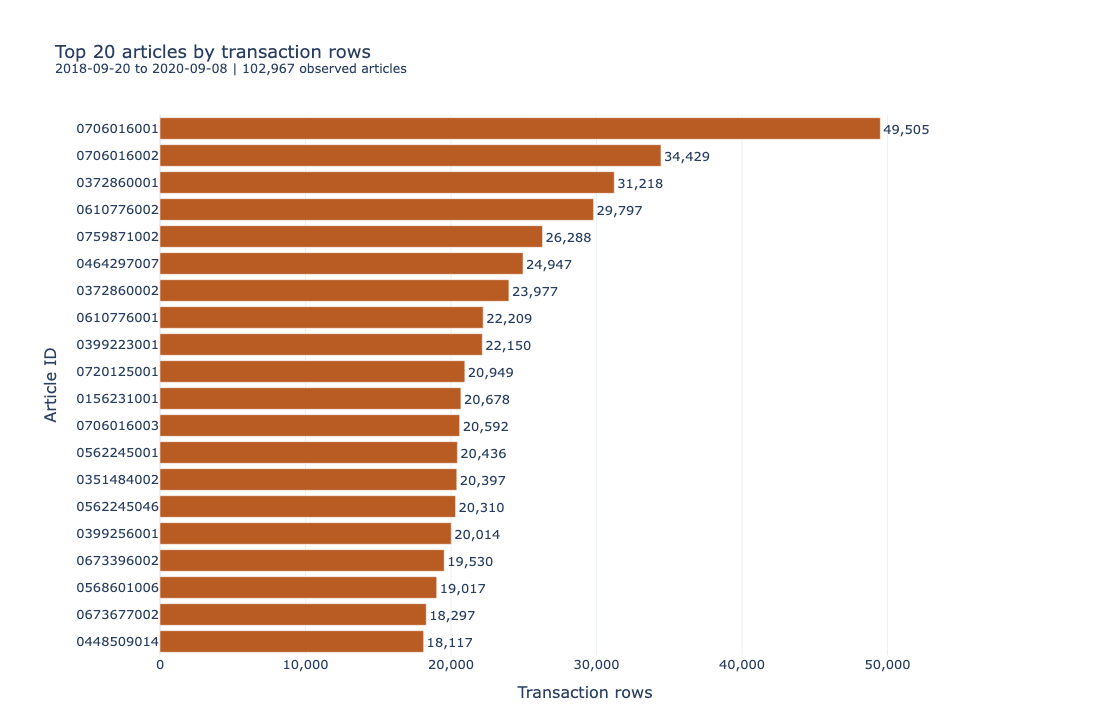

In [49]:
fig = make_article_popularity_figure(
    ranking=top_articles_by_rows,
    metric="transaction_rows",
    metric_label="Transaction rows",
    color="#B85C24",
)

fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

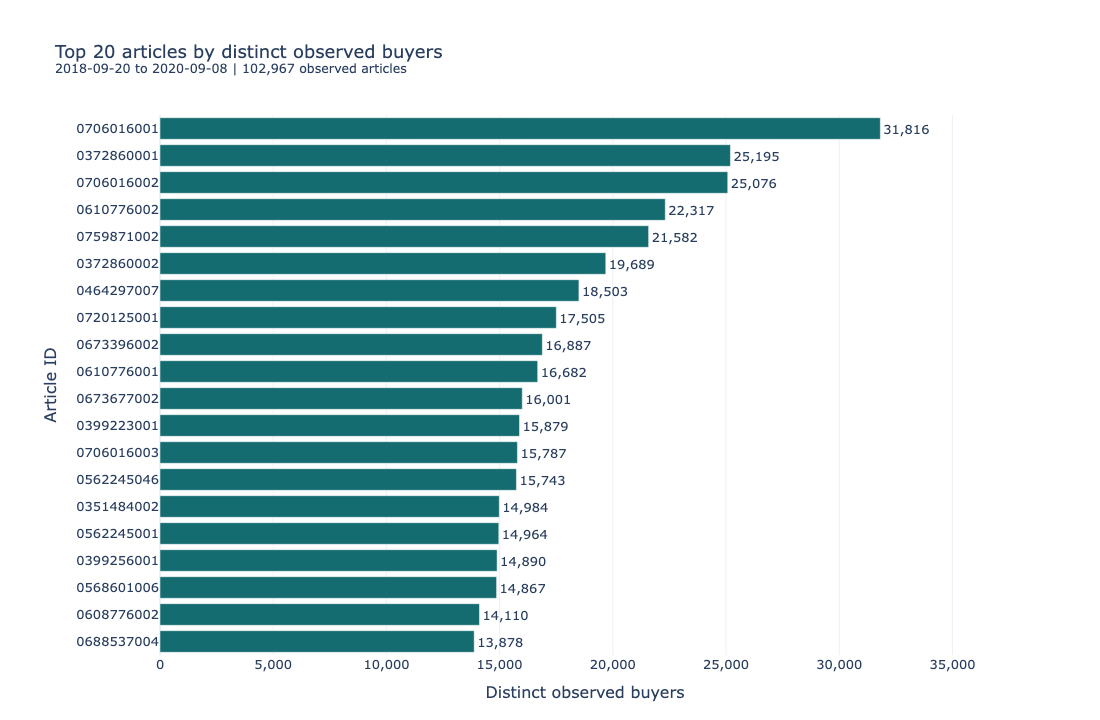

In [50]:
fig = make_article_popularity_figure(
    ranking=top_articles_by_buyers,
    metric="observed_buyers",
    metric_label="Distinct observed buyers",
    color="#146C70",
)

fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

### 5.8. Overlap Between Leading-Article Lists

Count articles appearing in both leading-article lists.

The overlap percentage uses the number of articles in either
equal-sized list as its denominator. It measures list similarity,
not customer coverage or recommendation performance.

In [51]:
top_row_article_ids = set(
    top_articles_by_rows["article_id"]
)

top_buyer_article_ids = set(
    top_articles_by_buyers["article_id"]
)

common_top_articles = (
    top_row_article_ids & top_buyer_article_ids
)

ranking_overlap_summary = pd.Series(
    {
        "articles_per_ranking": display_top_n,
        "articles_in_both_rankings": len(common_top_articles),
        "common_share_of_each_top_pct": round(
            100 * len(common_top_articles) / display_top_n,
            2,
        ),
    },
    name="value",
    dtype="object",
).rename_axis("measure").to_frame()

ranking_overlap_summary

,value
measure,
articles_per_ranking,20
articles_in_both_rankings,18
common_share_of_each_top_pct,90.0
